---
title: "American Time Use Survey: Exploratory Analysis"
subtitle: "ATUS 2003-2025"
author: "Maxwell Taylor"
date: last-modified

format:
  html:
    toc: true
    toc-depth: 3
    toc-location: right
    number-sections: true
    code-fold: true
    code-tools: true
    code-overflow: scroll

execute:
  echo: true
  warning: true
  message: false
---

In [22]:
# Load packages

library(tidyverse)
library(ggplot2)
library(ggthemes)
library(plotly)
library(dplyr)

Warning message:
"package 'ggthemes' was built under R version 4.6.2"


#========================================
# American Time Use Survey (ATUS) | 2003-2025
# Data Visualization Semester Project
# Maxell Taylor mct115
# Georgetown University
#
# Data Source: U.S. Breau of Labor Statistics
# https://www.bls.gov/tus/data.htm#
#
# Exploratory analysis of American time-use data
#========================================


In [ ]:

# Import data

# Total minutes per activity per respondent for one day by demographic
atus_sum <- read_csv(
  "data/raw/atussum_0325.dat",
  col_types = cols(
    TUCASEID = col_character(),
    .default = col_guess()
  )
)

# Additional respondent info such as employment, earnings, education
atus_resp <- read_csv(
  "data/raw/atusresp_0325.dat",
  col_types = cols(
    TUCASEID = col_character(),
    .default = col_guess()
  )
)

# Individual activities with stop time + duration
atus_act <- read_csv(
  "data/raw/atusact_0325.dat",
  col_types = cols(
    TUCASEID = col_character(),
    .default = col_guess()
  )
)


In [ ]:
# Initial exploration

# Dimensions
dim(atus_sum)  # 258954 x 456
dim(atus_resp) # 258954 x 133

# Column names --> join by TUCASEID
names(atus_sum)
names(atus_resp)

# Preview
head(atus_sum)
head(atus_resp)

[1] 258954    456

[1] 258954    133

[1] "TUCASEID"   "GEMETSTA"   "GTMETSTA"   "PEEDUCA"    "PEHSPNON"  
  [6] "PTDTRACE"   "TEAGE"      "TELFS"      "TEMJOT"     "TESCHENR"  
 [11] "TESCHLVL"   "TESEX"      "TESPEMPNOT" "TRCHILDNUM" "TRDPFTPT"  
 [16] "TRERNWA"    "TRHOLIDAY"  "TRSPFTPT"   "TRSPPRES"   "TRYHHCHILD"
 [21] "TUDIARYDAY" "TUFNWGTP"   "TEHRUSLT"   "TUYEAR"     "TU20FWGT"  
 [26] "t010101"    "t010102"    "t010199"    "t010201"    "t010299"   
 [31] "t010301"    "t010399"    "t010401"    "t010499"    "t010501"   
 [36] "t010599"    "t019999"    "t020101"    "t020102"    "t020103"   
 [41] "t020104"    "t020199"    "t020201"    "t020202"    "t020203"   
 [46] "t020299"    "t020301"    "t020302"    "t020303"    "t020399"   
 [51] "t020401"    "t020402"    "t020499"    "t020501"    "t020502"   
 [56] "t020599"    "t020681"    "t020699"    "t020701"    "t020799"   
 [61] "t020801"    "t020899"    "t020901"    "t020902"    "t020903"   
 [66] "t020904"    "t020905"    "t020999"    "t029999"    "t030101"   
 [71] "t030102"    "t030103"    "t030104"    "t030105"    "t030108"   
 [76] "t030109"    "t030110"    "t030111"    "t030112"    "t030186"   
 [81] "t030199"    "t030201"    "t030202"    "t030203"    "t030204"   
 [86] "t030299"    "t030301"    "t030302"    "t030303"    "t030399"   
 [91] "t030401"    "t030402"    "t030403"    "t030404"    "t030405"   
 [96] "t030499"    "t030501"    "t030502"    "t030503"    "t030504"   
[101] "t030599"    "t039999"    "t040101"    "t040102"    "t040103"   
[106] "t040104"    "t040105"    "t040108"    "t040109"    "t040110"   
[111] "t040111"    "t040112"    "t040186"    "t040199"    "t040201"   
[116] "t040202"    "t040203"    "t040204"    "t040299"    "t040301"   
[121] "t040302"    "t040303"    "t040399"    "t040401"    "t040402"   
[126] "t040403"    "t040404"    "t040405"    "t040499"    "t040501"   
[131] "t040502"    "t040503"    "t040504"    "t040505"    "t040506"   
[136] "t040507"    "t040508"    "t040599"    "t049999"    "t050101"   
[141] "t050102"    "t050103"    "t050189"    "t050201"    "t050202"   
[146] "t050203"    "t050204"    "t050289"    "t050301"    "t050302"   
[151] "t050303"    "t050304"    "t050389"    "t050403"    "t050404"   
[156] "t050405"    "t050481"    "t050499"    "t059999"    "t060101"   
[161] "t060102"    "t060103"    "t060104"    "t060199"    "t060201"   
[166] "t060202"    "t060203"    "t060289"    "t060301"    "t060302"   
[171] "t060303"    "t060399"    "t060401"    "t060402"    "t060403"   
[176] "t060499"    "t069999"    "t070101"    "t070102"    "t070103"   
[181] "t070104"    "t070105"    "t070199"    "t070201"    "t070299"   
[186] "t070301"    "t070399"    "t079999"    "t080101"    "t080102"   
[191] "t080199"    "t080201"    "t080202"    "t080203"    "t080299"   
[196] "t080301"    "t080302"    "t080399"    "t080401"    "t080402"   
[201] "t080403"    "t080499"    "t080501"    "t080502"    "t080599"   
[206] "t080601"    "t080602"    "t080699"    "t080701"    "t080702"   
[211] "t080799"    "t080801"    "t080899"    "t089999"    "t090101"   
[216] "t090102"    "t090103"    "t090104"    "t090199"    "t090201"   
[221] "t090202"    "t090299"    "t090301"    "t090302"    "t090399"   
[226] "t090401"    "t090402"    "t090499"    "t090501"    "t090502"   
[231] "t090599"    "t099999"    "t100101"    "t100102"    "t100103"   
[236] "t100199"    "t100201"    "t100299"    "t100381"    "t100383"   
[241] "t100399"    "t100401"    "t100499"    "t109999"    "t110101"   
[246] "t110199"    "t110281"    "t110289"    "t119999"    "t120101"   
[251] "t120199"    "t120201"    "t120202"    "t120299"    "t120301"   
[256] "t120302"    "t120303"    "t120304"    "t120305"    "t120306"   
[261] "t120307"    "t120308"    "t120309"    "t120310"    "t120311"   
[266] "t120312"    "t120313"    "t120399"    "t120401"    "t120402"   
[271] "t120403"    "t120404"    "t120405"    "t120499"    "t120501"   
[276] "t120502"    "t120503"    "t120504"    "t120599"    "t129999"   
[281] "t130101"    "t13010

[1] "TUCASEID"     "TULINENO"     "TESPUHRS"     "TRDTIND1"     "TRDTOCC1"    
  [6] "TRERNHLY"     "TRERNUPD"     "TRHERNAL"     "TRHHCHILD"    "TRIMIND1"    
 [11] "TRMJIND1"     "TRMJOCC1"     "TRMJOCGR"     "TRNHHCHILD"   "TRNUMHOU"    
 [16] "TROHHCHILD"   "TRTALONE"     "TRTCC"        "TRTHHFAMILY"  "TRTNOCHILD"  
 [21] "TRTNOHH"      "TRTO"         "TRTOHH"       "TRTOHHCHILD"  "TRTONHH"     
 [26] "TRTONHHCHILD" "TRTSPONLY"    "TRTSPOUSE"    "TRTUNMPART"   "TRWERNAL"    
 [31] "TTHR"         "TTOT"         "TTWK"         "TUABSOT"      "TUYEAR"      
 [36] "TEABSRSN"     "TEERN"        "TEERNH1O"     "TEERNH2"      "TEERNHRO"    
 [41] "TEERNHRY"     "TEERNPER"     "TEERNRT"      "TEERNUOT"     "TEERNWKP"    
 [46] "TEHRFTPT"     "TEHRUSL1"     "TEHRUSL2"     "TEIO1COW"     "TEIO1ICD"    
 [51] "TEIO1OCD"     "TELAYAVL"     "TELAYLK"      "TELKAVL"      "TELKM1"      
 [56] "TERET1"       "TESCHFT"      "TUBUS"        "TUBUS1"       "TUBUS2OT"    
 [61] "TUBUSL1"      "TUBUSL2"      "TUBUSL3"      "TUBUSL4"      "TUCC2"       
 [66] "TUCC4"        "TUFWK"        "TUIO1MFG"     "TUIODP1"      "TUIODP2"     
 [71] "TUIODP3"      "TULAY"        "TULAY6M"      "TULAYAVR"     "TULAYDT"     
 [76] "TULK"         "TULKAVR"      "TULKDK1"      "TULKDK2"      "TULKDK3"     
 [81] "TULKDK4"      "TULKM2"       "TULKM3"       "TULKM4"       "TULKM5"      
 [86] "TULKM6"       "TULKPS1"      "TULKPS2"      "TULKPS3"      "TULKPS4"     
 [91] "TUMONTH"      "TRTCCC"       "TRTCCTOT"     "TRTCHILD"     "TRTCOC"      
 [96] "TRTFAMILY"    "TRTFRIEND"    "TRTHH"        "TUDIS2"       "TURETOT"     
[101] "TUSPABS"      "TUSPUSFT"     "TUSPWK"       "TREMODR"      "TUCC9"       
[106] "TUDIARYDATE"  "TUDIS"        "TUDIS1"       "TRCHILDNUM"   "TUDIARYDAY"  
[111] "TRERNWA"      "TRHOLIDAY"    "TRSPFTPT"     "TRSPPRES"     "TRDPFTPT"    
[116] "TUFNWGTP"     "TESPEMPNOT"   "TESCHLVL"     "TESCHENR"     "TEMJOT"      
[121] "TELFS"        "TEHRUSLT"     "TRYHHCHILD"   "TRWBMODR"     "TRTALONE_WK" 
[126] "TRTCCC_WK"    "TRLVMODR"     "TRTEC"        "TUECYTD"      "TUELDER"     
[131] "TUELFREQ"     "TUELNUM"      "TU20FWGT"

TUCASEID,GEMETSTA,GTMETSTA,PEEDUCA,PEHSPNON,PTDTRACE,TEAGE,TELFS,TEMJOT,TESCHENR,⋯,t181801,t181899,t189999,t500101,t500103,t500104,t500105,t500106,t500107,t509989
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
20030100013280,1,-1,44,2,2,60,2,2,-1,⋯,0,0,0,0,0,0,0,0,0,0
20030100013344,2,-1,40,2,1,41,1,2,2,⋯,0,0,0,0,0,0,0,0,0,0
20030100013352,1,-1,41,2,1,26,2,2,2,⋯,0,0,0,0,0,0,0,0,0,0
20030100013848,2,-1,39,2,2,36,4,-1,2,⋯,0,0,0,0,0,0,0,0,0,0
20030100014165,2,-1,45,2,1,51,1,2,-1,⋯,0,0,0,0,0,0,0,0,0,0
20030100014169,2,-1,43,2,1,32,2,2,1,⋯,0,0,0,0,0,0,0,0,0,0


TUCASEID,TULINENO,TESPUHRS,TRDTIND1,TRDTOCC1,TRERNHLY,TRERNUPD,TRHERNAL,TRHHCHILD,TRIMIND1,⋯,TRWBMODR,TRTALONE_WK,TRTCCC_WK,TRLVMODR,TRTEC,TUECYTD,TUELDER,TUELFREQ,TUELNUM,TU20FWGT
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
20030100013280,1,-1,40,8,2200,1,1,2,15,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100013344,1,50,16,16,-1,1,-1,1,5,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100013352,1,-1,43,15,1250,0,0,2,16,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100013848,1,40,-1,-1,-1,-1,-1,1,-1,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100014165,1,-1,42,10,-1,-1,-1,1,16,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100014169,1,40,40,8,-1,1,-1,1,15,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1


In [14]:
# Check duplicate respondent IDs --> none

atus_sum |> count(TUCASEID) |> filter(n > 1)
atus_resp |> count(TUCASEID) |> filter(n > 1)

# df is way to big to parse visually, split as follows

# Identify activity columns

# used ChatGPT for pattern syntax: ^ = beginning of string,
# {6} = repetitions of pattern, $ = end of string
activity_columns <- names(atus_sum)[
  grepl("^t[0-9]{6}$", names(atus_sum))
]

length(activity_columns)
head(activity_columns)

respondent_columns <- setdiff(
  names(atus_sum),
  activity_columns
)
respondent_columns

TUCASEID,n
<chr>,<int>


TUCASEID,n
<chr>,<int>


[1] 431

[1] "t010101" "t010102" "t010199" "t010201" "t010299" "t010301"

[1] "TUCASEID"   "GEMETSTA"   "GTMETSTA"   "PEEDUCA"    "PEHSPNON"  
 [6] "PTDTRACE"   "TEAGE"      "TELFS"      "TEMJOT"     "TESCHENR"  
[11] "TESCHLVL"   "TESEX"      "TESPEMPNOT" "TRCHILDNUM" "TRDPFTPT"  
[16] "TRERNWA"    "TRHOLIDAY"  "TRSPFTPT"   "TRSPPRES"   "TRYHHCHILD"
[21] "TUDIARYDAY" "TUFNWGTP"   "TEHRUSLT"   "TUYEAR"     "TU20FWGT"

In [ ]:
# Data preperation

# Respondent columns not already in summary
resp_extra <- setdiff(
    names(atus_resp),
    names(atus_sum)
)
length(resp_extra) # 115

# Join additional information using TUCASEID
atus_full <- atus_sum |>
  left_join(
    atus_resp |>
      select(TUCASEID, all_of(resp_extra)),
    by = "TUCASEID",
    relationship = "one-to-one"
  )

# Verify
dim(atus_full) # 258954 x 571

# Check for unmatched respondent IDs 
nrow(anti_join(atus_sum, atus_resp, by = "TUCASEID")) # = 0, so verified

[1] 115

[1] 258954    571

[1] 0

TUYEAR,n
<dbl>,<int>
2003,20720
2004,13973
2005,13038
2006,12943
2007,12248
2008,12723
2009,13133
2010,13260
2011,12479


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  15.00   34.00   47.00   48.45   63.00   85.00 

TESEX,n
<dbl>,<int>
1,114974
2,143980


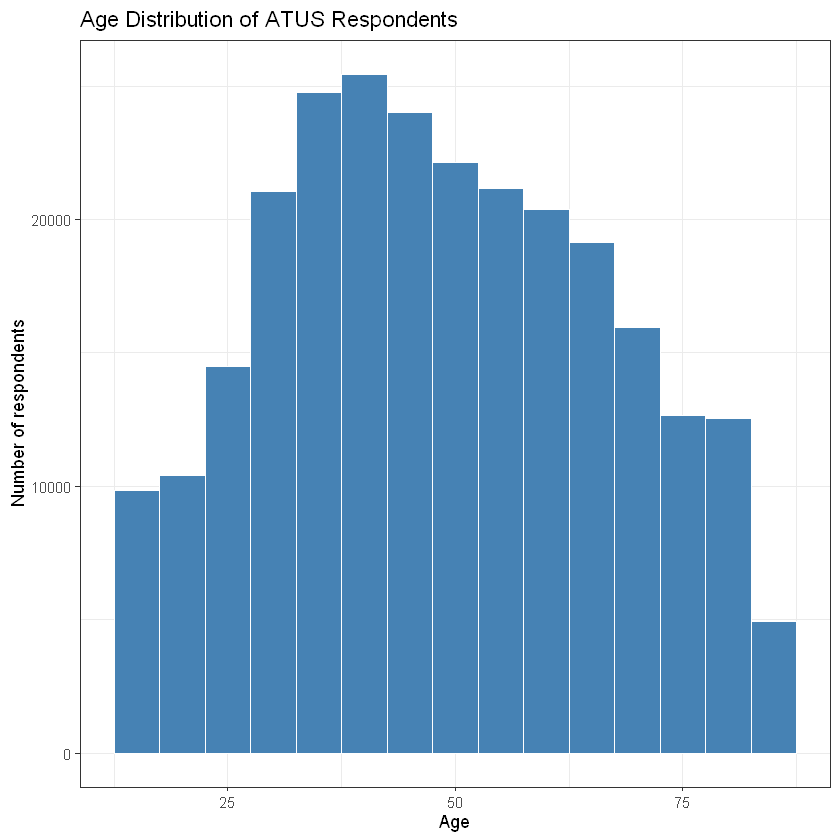

In [ ]:
# Respondent characteristics exploration

# respondents per year
atus_sum |> count(TUYEAR)

# Age distribution
summary(atus_sum$TEAGE)

p_age <- ggplot(atus_sum, aes(x = TEAGE)) +
  geom_histogram(binwidth = 5, fill = "steelblue", color = "white") +
  labs(
    title = "Age Distribution of ATUS Respondents",
    x = "Age",
    y = "Number of respondents"
  ) +
  theme_bw()

p_age

# Sex distribution
atus_sum |> count(TESEX)
# 1 = male, 2 = female
# 114974 male (44.4%) vs 143980 female (55.6%)


In [ ]:
# Activity variable inventory


activity_inventory <- tibble(
  code = activity_columns, # breaks each tabcdef into parasable pices
  #broad category (e.g., 01 = Personal Care Activities, 02 = Household activities)
  tier_1 = substr(activity_columns, 2, 3),
  #sub-category (e.g., 0101 = sleeping, 0102 = grooming)
  tier_2 = substr(activity_columns, 2, 5),
  #specific-activity (e.g., 010101 = sleeping, 010102 = sleeplessness)
  tier_3 = substr(activity_columns, 2, 7)
)


# How many activity codes per broad category?
activity_inventory |>
  count(tier_1, name = "n_codes") |>
  arrange(tier_1)

# Examine
head(activity_inventory, 20) # utilize Analysis\Data\Raw\lexiconnoex0325.pdf

tier_1,n_codes
<chr>,<int>
01,12
02,32
03,33
04,37
05,20
06,18
07,11
08,26
09,18


code,tier_1,tier_2,tier_3
<chr>,<chr>,<chr>,<chr>
t010101,01,0101,010101
t010102,01,0101,010102
t010199,01,0101,010199
t010201,01,0102,010201
t010299,01,0102,010299
t010301,01,0103,010301
t010399,01,0103,010399
t010401,01,0104,010401
t010499,01,0104,010499


In [52]:
# Activity variable profiles

# table describing the structure of data
activity_profile <- map_dfr(activity_columns, function(code) {
  x <- atus_full[[code]]

  tibble(
    code = code,
    # number of respondents with positive minutes for activity
    n_positive = sum(x > 0, na.rm = TRUE),
    # Percentage of respondents with nonmissing values who recorded positive minutes
    pct_positive = round(mean(x > 0, na.rm = TRUE) * 100, 2),
    n_missing = sum(is.na(x)),
    # for respondent variables: -1 = blank, -2 = Don't know, -3 = Refused
    n_negative = sum(x < 0, na.rm = TRUE),
    n_distinct = n_distinct(x)
  )
})

# Combine with activity hierarchy
activity_profile <- activity_profile |>
  left_join(activity_inventory, by = "code")

# Most frequently recorded activities
activity_profile |>
  arrange(desc(n_positive)) |>
  head(15)

# Least frequently recorded activities
activity_profile |>
  filter(n_positive > 0) |>
  arrange(n_positive) |>
  head(15)

# How many codes have no positive observations?
sum(activity_profile$n_positive == 0) #5
activity_profile |> filter(n_positive == 0)

code,n_positive,pct_positive,n_missing,n_negative,n_distinct,tier_1,tier_2,tier_3
<chr>,<int>,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>
t010101,258589,99.86,0,0,1175,01,0101,010101
t110101,247373,95.53,0,0,475,11,1101,110101
t120303,206559,79.77,0,0,1125,12,1203,120303
t010201,200284,77.34,0,0,315,01,0102,010201
t020201,143062,55.25,0,0,436,02,0202,020201
t120101,91962,35.51,0,0,726,12,1201,120101
t050101,89684,34.63,0,0,1067,05,0501,050101
t180782,79604,30.74,0,0,424,18,1807,180782
t180501,70379,27.18,0,0,338,18,1805,180501


code,n_positive,pct_positive,n_missing,n_negative,n_distinct,tier_1,tier_2,tier_3
<chr>,<int>,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>
t010599,1,0,0,0,2,01,0105,010599
t070399,1,0,0,0,2,07,0703,070399
t100499,1,0,0,0,2,10,1004,100499
t040204,2,0,0,0,3,04,0402,040204
t130111,2,0,0,0,3,13,1301,130111
t130201,2,0,0,0,3,13,1302,130201
t130211,2,0,0,0,3,13,1302,130211
t130230,2,0,0,0,3,13,1302,130230
t140104,2,0,0,0,3,14,1401,140104


[1] 5

code,n_positive,pct_positive,n_missing,n_negative,n_distinct,tier_1,tier_2,tier_3
<chr>,<int>,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>
t080899,0,0,0,0,1,08,0808,080899
t110199,0,0,0,0,1,11,1101,110199
t130208,0,0,0,0,1,13,1302,130208
t130228,0,0,0,0,1,13,1302,130228
t130499,0,0,0,0,1,13,1304,130499


In [55]:
# Respondent variable inventory

# 25 non-activity variables from atus_sum
# + 115 additional variables from atus_resp
resp_columns <- c(respondent_columns, resp_extra)

resp_inventory <- tibble(
  variable = resp_columns,
  type = sapply( # apply function to each column
    atus_full[resp_columns], # the 140 non-activity variables
    function(x) class(x)[1] # returns the first class of x = atus_full[...]
  ) |> unname()
)

resp_inventory

variable,type
<chr>,<chr>
TUCASEID,character
GEMETSTA,numeric
GTMETSTA,numeric
PEEDUCA,numeric
PEHSPNON,numeric
PTDTRACE,numeric
TEAGE,numeric
TELFS,numeric
TEMJOT,numeric


In [ ]:
# Examine selected respondent variables

# KEY:
# Analysis\Data\Raw\atuscpscodebk0325.pdf
# Analysis\Data\Raw\atusintcodebk0325.interview.pdf
# e.g., PEEDUCA --> p = personal, e = edited, educa = education
# for respondent variables: -1 = blank, -2 = Don't know, -3 = Refused

# Education
atus_full |> count(PEEDUCA, sort = TRUE)
# 31 = less than 1st grade --> 46 = Doctoral degree
# 39 = HS Diploma, 43 = Bachelor's

# Labor force status
atus_full |> count(TELFS, sort = TRUE)
# 1 = employed at work --> 5 = not in labor force

# School enrollment
atus_full |> count(TESCHENR, sort = TRUE)
# 1 = yes, 2 = no
# -1 = blank, -3 = refused

PEEDUCA,n
<dbl>,<int>
39,65287
43,54409
40,44412
44,25057
42,13502
41,11169
37,8025
36,7660
35,6690


TELFS,n
<dbl>,<int>
1,151737
5,89393
4,9663
2,6956
3,1205


TESCHENR,n
<dbl>,<int>
-1,119947
2,116468
1,22536
-3,3


In [ ]:
# Data availablity by year

selected_code <- "t010101"

atus_full |>
  group_by(TUYEAR) |>
  summarise(
    n = n(),
    pct_missing = round(
      mean(is.na(.data[[selected_code]])) * 100, 2
    ),
    pct_positive = round(
      mean(.data[[selected_code]] > 0, na.rm = TRUE) * 100, 2
    ),
    .groups = "drop"
  )

# HOWEVER: Disclaimer on 2020

TUYEAR,n,pct_missing,pct_positive
<dbl>,<int>,<dbl>,<dbl>
2003,20720,0,99.83
2004,13973,0,99.90
2005,13038,0,99.87
2006,12943,0,99.89
2007,12248,0,99.87
2008,12723,0,99.89
2009,13133,0,99.90
2010,13260,0,99.83
2011,12479,0,99.90


**Disclaimer on 2020**

> "The 2020 ATUS was greatly affected by the coronavirus (COVID-19) pandemic. Data collection was suspended in 2020 from mid-March to mid-May. ATUS data files for 2020 contain all ATUS data collected in 2020—both before and after data collection was suspended. For more information, please see the [Impact of the COVID-19 pandemic on the 2020 ATUS page](https://www.bls.gov/tus/notices/2021/covid19.htm)."

https://www.bls.gov/tus/data/datafiles-0325.htm?utm_source=chatgpt.com

In [63]:
# Exclude 2020 for when comparison requires full year
atus_complete_years <- atus_full |>
  filter(TUYEAR != 2020)

# Verify
atus_complete_years |>
  count(TUYEAR)

TUYEAR,n
<dbl>,<int>
2003,20720
2004,13973
2005,13038
2006,12943
2007,12248
2008,12723
2009,13133
2010,13260
2011,12479


# ATUS Exploratory Analysis Reference Guide

## 1. Main Dataframes

| Object | Contents | Use |
|---|---|---|
| `atus_sum`| Original Activity Summary: 258,954 rows x 456 columns | Exploring activity durations and basic respondent info |
| `atus_resp` | Original Respondent file: 258,954 x 133 | Examining additional respondent variables |
| `atus_act` | Original Activity file | Analyzing activity episodes rather than daily totals |
| `atus_full` | Activity Summary + 115 additional respondent columns: 258.954 x 571 | Main dataset for analyses requiring both activity and respondent info|
| `atus_complete_years` | `atus_full` excluding respondents surveyed in 2020 | Comparisons across/between complete calandar years |

**Important:**
- ALL original datasets unchanged
- `atus_sum` and `atus_resp` joined using `TUCASEID`, with one-to-one relationship and no unmatched IDs
- `atus_act` has multiple records per respondent and should NOT be joined directly without accounting for this
- `atus_complete_years` excludes 2020 due to pandemic-related interruption in data collection (see above disclaimer)

## 2. Column Reference Objects

| Object | Contents | Usage |
| --- | --- | --- |
| `activity_columns` | Vector of 431 activity-duration column names | Select or loop through activity variables |
| `respondent_columns` | Vector of 25 non-activity column names from `atus_sum` | Identify original respondent variables |
| `resp_extra` |Vector of 115 columns unique to `atus_resp` | Identify additional respondent information |
| `resp_columns` | Combined vector of 140 non-activity column names | Reference ALL respondent variables in `atus_full` |


## 3. Inventory and Profile Tables

### `activity_inventory`
One row per activity code, containing:
- `code`: Original ATUS activity variable name
- `tier_1`: Broad activity category (first two digits)
- `tier_2`: Subcategory (first four digits)
- `tier_3`: Specific activity (all six digits)

**Use:** Understanding the activity classification hierarchy, and locating codes in the Activity Lexicon

### `activity_profile`
One row per acticity code, containing:
- `code`: ATUS activity variable
- `n_positive`: Number of respondents reporting positive minutes
- `pct_positive`: Percentage of nonissing observations reporting positive minutes
- `n_missing`: Number of missing values
- `n_negative`: Number of negative values (see above key)
- `n_distinct`: Number of distinct recorded values
- `tier_1`, `tier_2`, `tier_3`: Activity classification hierarchy

**Use**: Identifying common/rare activities, checking data completeness, investigating unusual values

### `resp_inventory`
One row per non-activity variable, containing:
- `variable`: Original ATUS variable name
- `tpye`: R data class

**Use**: Identifying available respondent variables and checking how R imported them (some ought to be factored/otherwise altered)

**Note:** Some variables are numeric, but not continuous. Many characteristics are numerically coded categories.

## 4. Documentation and Codebooks

Located in `Analysis/Data/Raw/`:
- `lexiconnoex0325.pdf` - Activity Coding Lexicon; identifies meanings of activity codes
- `atuscpscodebk0325.pdf` - ATUS-CPS Data Dictionary; includes demographic variables such as `PEEDUCA`
- `atusintcodebk0325.interview.pdf` - ATUS Interview Data Dictionary; includes interview-related respondent variables

[Original Data Souce](https://www.bls.gov/tus/data/datafiles-0325.htm)

## 5. Important Data Considerations

**Survey structure**
- Activity Summary contains one row per respondent
- Activity variables measure minutes spent on an activity during one diary day.
- Zero minutes generally means that activity wass not recorded on that day
- The Activity file records individual activity episodes, not one row per respondent

**Respondent coding**
- Many categorical variables use numeric codes
- Special values may incude -1 (blank), -2 (don't know), and -3 (refused)
- Consult the corresponding data dictionary before interpreting values or replacing them with NA

**Survey weighting**
- Current counts, distributions, and `activity_profile` percentages are unweighted sample descriptions
- Population-level time-use estimates require appropriate AGUS survey weights
- `TUFNWGTP` is the standard final weight for most years, but 2020 requires special treatment

**2020**
- ATUS collection suspended from mid-march to mid-may 2020
- Full-year estimates for 2020 are not representative
- Preserve 2020 in `atus_full`, but use `atus_complete_years` when comparing complete calendar years
- Special 2020 comparisons require differing weights
